# Baseline evaluation for on-policy distillation

**Notebook 02 · Reproducible inference, auditable scoring, and an honest starting point**

Before teaching a small language model, establish what it can already do and
what the measurement actually counts. This notebook studies **one unchanged
Qwen3 student on 32 fixed arithmetic questions**. It preserves the original
format-sensitive score and reports a separate, explicitly exploratory prose score.

| Experiment | Definition |
| :--- | :--- |
| Student | `Qwen/Qwen3-0.6B-Base`, original pretrained checkpoint |
| Questions | 32 fixed examples from the pinned GSM8K test split |
| Decoding | Greedy, one beam, at most 512 new tokens |
| Primary measure | Original strict-format numeric accuracy, all questions included |
| Secondary measure | Prose-extracted numeric accuracy, designed after inspecting this run |
| Execution provenance | Mode and fresh-inference status are printed below and exported with each run |
| Scope | No teacher loading, optimization, or training in this notebook |

> **Evidence, not a benchmark claim.** The recorded responses were generated on an
> A100 on 27 October 2026. Replay verifies and analyzes those exact bytes. The
> alternative `generate` mode performs fresh inference on a connected CUDA runtime.
> These modes are labeled in the outputs and exported metadata.

**Contents:** [1. Motivation](#motivation) · [2. Research foundations](#research) ·
[3. Protocol](#protocol) · [4. Implementation](#implementation) ·
[5. Results](#results) · [6. Reproducibility](#reproducibility) · [7. Conclusions](#conclusions)


---

<a id="motivation"></a>

## 1. Motivation: separate model behavior from measurement behavior

Notebook 01 established the mechanics of student generation, teacher scoring,
reverse KL, and one student update. That does not establish improved task performance.
Here we reload or analyze the **original** student, never the updated in-memory model.

The first baseline produced no `####` final answers. A strict score of zero can
therefore coexist with numerically correct conclusions written in prose. We ask:

1. Can we reproduce the recorded experiment and its original score?
2. How much of the measurement failure comes from answer extraction?
3. Which failures remain visible after a conservative prose checker is added?

This is an educational adaptation of the research workflow, not a replication of
the paper's models, training settings, or published benchmark scores.

### The idea in everyday terms

Think of this notebook as a **test before lessons begin**. Notebook 01 checked
that the teaching machinery works on one response. Notebook 02 asks what the
original student can do across a small, fixed set of questions.

For example, if a model writes “There are 12 pencils left” when we requested
`#### 12`, two different things happened: it may have found the right number,
but it did not follow the requested output format. We keep those observations
separate rather than treating either score as the whole story.

**By the end:** you should be able to explain where the questions came from,
what the student wrote, how each answer was scored, and what the scores cannot prove.

### Run this notebook

- **Local CPU:** install `requirements-notebook.txt` into a separate Python 3.12+
  environment, select that Jupyter kernel, set `MODE = "replay"`, and run all cells.
- **Colab, including a VS Code Colab kernel:** the setup cell locates the project
  or clones its public `dev` branch into `/content`, without Google Drive. It installs
  the analysis libraries and, in `generate` mode, the pinned Hugging Face helpers. After installation, the setup cell
  intentionally stops and asks you to restart the kernel. Restart it, then run all
  cells from the top. This keeps older loaded libraries from mixing with new ones,
  including pandas, NumPy, and pandas' optional `bottleneck` accelerator.
  The setup upgrades Colab's older `bottleneck` to a compatible version. If a pandas error persists after the
  restart, keep the full traceback so we can identify the exact cause.
- Use `MODE = "replay"` for analysis of the recorded run. Use `"generate"`
  only for a fresh run on your A100 or L4. The latter downloads the student weights
  and the pinned dataset; it does not load the 32B teacher.

The local validation command is `python scripts/validate_notebook02.py`.

**Setup checkpoint:** `generate` means “ask the model to answer now.” `replay`
means “read answers saved earlier and check them again.” Replaying a test is like
remarking an existing exam paper. It cannot produce new model behavior.
The setup cell currently defaults to `generate`; edit `MODE` to choose `replay`.
A kernel restart clears Python's memory, so you must then rerun from the top.


In [1]:
import importlib.metadata
import os
import subprocess
import sys
import tempfile
from pathlib import Path

# This choice controls execution, not the evaluation questions or scoring policy.
MODE = os.environ.get("OPD_NOTEBOOK_MODE", "generate")  # Use "replay" to analyze the saved run without inference.
if MODE not in {"replay", "generate"}:
    raise ValueError("MODE must be 'replay' or 'generate'.")

try:
    import google.colab  # noqa: F401
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

# A remote Colab kernel cannot see your local VS Code files automatically.
# Find a checkout first; otherwise obtain the public project on the remote runtime.
PROJECT_ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "src/baseline.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    if not IN_COLAB:
        raise RuntimeError("Start Jupyter inside the cloned on-policy-distillation project.")
    PROJECT_ROOT = Path("/content/on-policy-distillation")
    if not PROJECT_ROOT.exists():
        subprocess.run(
            ["git", "clone", "--quiet", "--depth", "1", "--branch", "dev",
             "https://github.com/igoldin670/on-policy-distillation.git", str(PROJECT_ROOT)],
            check=True,
        )
    if not (PROJECT_ROOT / "src/baseline.py").is_file():
        raise RuntimeError("Use a current project checkout containing src/baseline.py.")


def install_with_uv(requirements):
    "Install into this kernel's interpreter, not an unrelated local environment."
    import importlib.util
    if importlib.util.find_spec("uv") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "uv"], check=True)
    subprocess.run(
        [sys.executable, "-m", "uv", "pip", "install", "--python", sys.executable, *requirements],
        check=True, capture_output=True, text=True,
    )


if IN_COLAB:
    # Preserve Colab's working kernel and PyTorch/CUDA stack. The full lock file
    # is for a separate local environment; Colab installs analysis libraries and,
    # in generate mode, the pinned Hugging Face helpers. PyTorch is left in place.
    analysis_packages = [line for line in (PROJECT_ROOT / "requirements-notebook.txt").read_text().splitlines()
                         if line.split("==")[0] in {"numpy", "pandas", "matplotlib"}]
    # Colab can include bottleneck 1.4.2, which is too old for this pandas.
    # Pin its optional numeric accelerator too, instead of hiding the warning.
    analysis_packages.append("bottleneck==1.5.0")
    if MODE == "generate":
        # Install generation helpers here too, before importing model libraries.
        # Replacing an imported library later would require another restart.
        analysis_packages.extend(
            line.strip()
            for line in (PROJECT_ROOT / "requirements-generation.txt").read_text().splitlines()
            if line.strip() and not line.lstrip().startswith("#")
        )

    def needs_install(item):
        name, version = item.split("==")
        try:
            return importlib.metadata.version(name) != version
        except importlib.metadata.PackageNotFoundError:
            return True

    # Colab may import these libraries before this cell runs. Installing a new
    # version changes files on disk, but does not replace already loaded code.
    # Continuing can mix incompatible versions inside one running kernel.
    for package_name in (
        "numpy", "pandas", "matplotlib", "bottleneck",
        "transformers", "datasets", "accelerate", "huggingface_hub",
    ):
        loaded_package = sys.modules.get(package_name)
        if loaded_package is not None:
            loaded_version = getattr(loaded_package, "__version__", None)
            installed_version = importlib.metadata.version(package_name)
            if loaded_version is not None and loaded_version != installed_version:
                raise RuntimeError(
                    f"{package_name} {loaded_version} is loaded, but {installed_version} "
                    "is installed. Restart the Colab kernel, then run all cells from the top. "
                    "Rerunning this cell alone cannot refresh loaded libraries."
                )

    if any(needs_install(item) for item in analysis_packages):
        install_with_uv(analysis_packages)
        # Require a fresh process even if a dependency was imported indirectly.
        # This intentional stop prevents confusing errors later in the diagrams.
        raise RuntimeError(
            "Notebook dependencies were installed successfully. Restart the Colab kernel "
            "now, then run all cells from the top. No model has been loaded yet."
        )

# Use a writable font cache in restricted environments. No credentials are needed.
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "opd-matplotlib"))
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"Execution mode: {MODE.upper()} | In Colab: {IN_COLAB}")


Execution mode: GENERATE | In Colab: True


In [2]:
import math
from datetime import datetime, timezone

import pandas as pd
from IPython.display import Image, display

from src.baseline import (
    analysis_environment, export_analysis, generate_fresh_baseline,
    metric_rows, verify_recorded_run,
)
from src.baseline_plots import (
    plot_distillation_context, plot_evaluation_workflow,
    plot_metric_comparison, plot_response_lengths,
)
from src.evaluation import PROSE_CHECKER_VERSION, categorical_kl

# Keep raw evidence and generated graphics separate. Figure paths remain relative
# to this notebook on GitHub, and no notebook attachment support is required.
# The four source-run figures are checked in; a fresh local run may regenerate them.
ASSETS = PROJECT_ROOT / "notebooks/assets/02_baseline_evaluation"
FIGURES = ASSETS / "figures"
RECORDED_RUN = ASSETS / "recorded_run"
pd.set_option("display.max_colwidth", 72)
print("Checker:", PROSE_CHECKER_VERSION)
print("Analysis Python:", analysis_environment()["python"])

# Record the active pandas version so a Colab-specific error can be diagnosed.
print("Analysis pandas:", pd.__version__)


Checker: clear_final_numeric_answer_v2
Analysis Python: 3.13.16
Analysis pandas: 3.1.0


---

<a id="research"></a>

## 2. Research foundations: what this baseline will support

> **Goal:** Understand why we need a task baseline before judging distillation.

The **student** is the small model we want to improve. The **teacher** is a larger,
frozen model that will provide next-token feedback during distillation. “Frozen”
means its learned weights stay fixed. Notebook 02 only tests the student; the
teacher in the diagram is context for later training.

### Read the notation as a next-word question

Imagine the prompt is “What is 2 + 2?” and the student has written “The answer is”.
That prompt plus the words already written is the **prefix**. Both models can
assign probabilities to possible next tokens such as `4`, `5`, or punctuation.
The prefix does not include the token we are asking them to predict.

In the notation below, $x$ is the question, $y$ is the response, $y_{<t}$ means
“response tokens before position $t$,” and $v$ is one possible next token.
$\theta$ represents the student's learned weights. The vertical bar in
$p_S^\theta(v\mid x,y_{<t})$ means “given this prompt and earlier response.”

Let $x$ be a prompt, $y=(y_1,\ldots,y_T)$ a response, and $V$ a shared token vocabulary.
The student $p_S^\theta(v\mid x,y_{<t})$ and frozen teacher $p_T(v\mid x,y_{<t})$
assign probabilities to the **same next token after the same prefix**.

The project's teacher is `Qwen/Qwen3-32B`, used in notebook 01. It appears here
only to explain the research architecture; its weights are not loaded.

In [Generalized Knowledge Distillation, Section 3](https://arxiv.org/html/2306.13649v3#S3),
student-generated prefixes allow teacher feedback on states the student actually
visits. Fixed human or teacher-generated sequences supply an off-policy alternative.
Sampling current-student trajectories and keeping the teacher frozen are distinct
from asking a model to grade whether its own answer is correct.

**On-policy versus off-policy, with an example.** Suppose the student makes an
arithmetic mistake halfway through its answer. On-policy distillation lets the
teacher give feedback after that actual student-written prefix. Training only
on polished teacher-written answers would show a different set of prefixes.
The distinction is **who produced the sequence used for training**, not whether
the model being tested is large or small. This notebook performs neither kind of training.


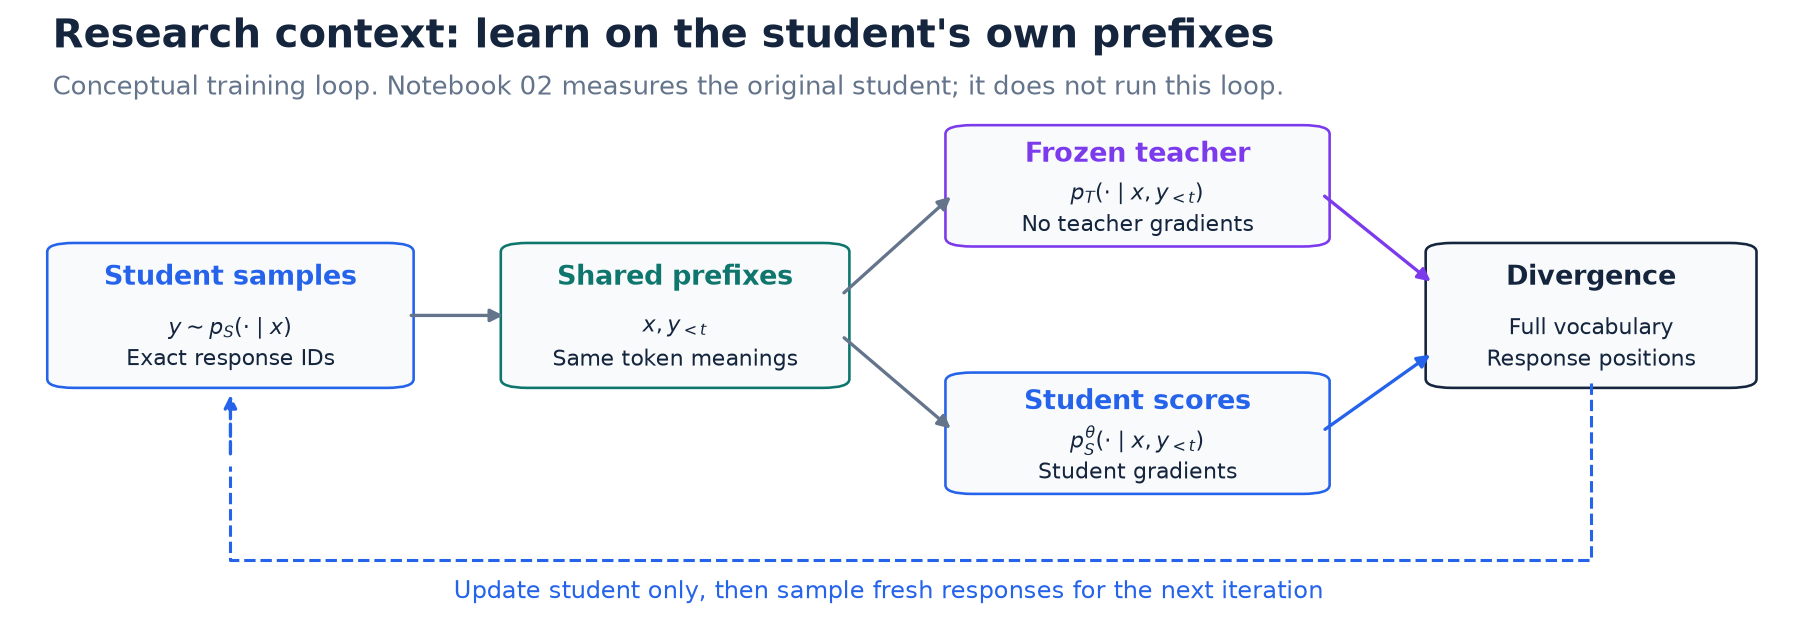

In [3]:
# This is a conceptual architecture diagram, not a trace from this baseline run.
context_figure = plot_distillation_context(FIGURES)
display(Image(filename=str(context_figure)))


*Figure 1. The training loop that this baseline will later help evaluate. Teacher
and student score identical prefixes; only student parameters receive updates.
Notebook 02 executes the evaluation path, not this training loop.*
[PNG](assets/02_baseline_evaluation/figures/distillation_context.png) ·
[SVG](assets/02_baseline_evaluation/figures/distillation_context.svg)

### 2.1 KL divergence compares full distributions

### A distribution is a whole menu of next-token possibilities

In a toy vocabulary, the student might assign probabilities `[0.6, 0.3, 0.1]`
to tokens `A`, `B`, and `C`; the teacher might assign `[0.7, 0.2, 0.1]`.
Each list adds to 1. Even if both choose `A`, they disagree about the alternatives.
KL divergence summarizes that disagreement across the whole list.

For reverse KL, the contribution for `A` is
`0.6 * log(0.6 / 0.7)`, and we add the contributions for `B` and `C`.
Individual contributions can be negative; the complete KL sum is nonnegative
in exact arithmetic. `categorical_kl` below performs that sum.
These are invented probabilities, not outputs from our Qwen models.

For categorical distributions $P$ and $Q$ over $V$, using natural logarithms,

$$
D_{\mathrm{KL}}(P\Vert Q)
=\mathbb{E}_{v\sim P}\left[\log\frac{P(v)}{Q(v)}\right]
=\sum_{v\in V}P(v)\bigl(\log P(v)-\log Q(v)\bigr).
$$

The result is measured in **nats**. It is nonnegative in exact arithmetic, is zero
when the distributions match, and is generally asymmetric. A positive $P(v)$ with
$Q(v)=0$ makes it infinite. Terms with $P(v)=0$ contribute zero.

Forward KL, $D_{\mathrm{KL}}(p_T\Vert p_S)$, weights tokens by teacher probabilities.
Because $D_{\mathrm{KL}}(p_T\Vert p_S)=H(p_T,p_S)-H(p_T)$ and the teacher is fixed,
minimizing it is equivalent to minimizing teacher-target cross-entropy. Reverse KL,
$D_{\mathrm{KL}}(p_S\Vert p_T)=H(p_S,p_T)-H(p_S)$, instead uses student weights;
the student entropy also changes. Neither expression is merely the difference
between two selected-token log probabilities.

The next cell implements the sum directly through `categorical_kl`. These are
**invented three-token distributions for a numerical sanity check**, not model
measurements. For framework conventions, see [PyTorch's KL documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.KLDivLoss.html).

**How to read the result:** zero means identical distributions. A larger value
means more disagreement in the specified direction. Reversing the arguments
changes whose probabilities weight the disagreement, so it usually changes the
answer. KL is not a percentage of wrong answers. “Nats” simply means that we
used natural logarithms; there is no accuracy threshold such as “below 0.1 is good.”

The entropy identities above explain the training objectives. **Entropy** measures
how spread out one distribution is; **cross-entropy** measures how one distribution
fits another's probability assignments. You can follow the evaluation without
memorizing these identities.


In [4]:
# Synthetic distributions isolate the mathematics from model loading and tokenization.
example_student = [0.6, 0.3, 0.1]
example_teacher = [0.7, 0.2, 0.1]
reverse_kl_example = categorical_kl(example_student, example_teacher)
forward_kl_example = categorical_kl(example_teacher, example_student)
assert math.isclose(categorical_kl(example_student, example_student), 0.0, abs_tol=1e-12)
assert reverse_kl_example > 0 and forward_kl_example > 0
assert not math.isclose(reverse_kl_example, forward_kl_example, abs_tol=1e-8)
display(pd.DataFrame({
    "Illustrative calculation (not model results)": ["Reverse KL: student || teacher", "Forward KL: teacher || student"],
    "nats": [reverse_kl_example, forward_kl_example],
}).set_index("Illustrative calculation (not model results)").round(6))


,nats
Illustrative calculation (not model results),
Reverse KL: student || teacher,0.029149
Forward KL: teacher || student,0.026812


### 2.2 From a token divergence to an on-policy loss

**Two averages, two different jobs.** First compare the models' vocabulary
probabilities at one response position. Then average those comparisons across
the response. If three positions have toy KL values `0.1`, `0.3`, and `0.2`,
the response's mean is `(0.1 + 0.3 + 0.2) / 3 = 0.2` nats.
A **loss** is a number training tries to reduce. Here the loss is explained for
context; the next code block is a Markdown example and does not run.

For a fixed sampled trajectory, average reverse KL across its response positions:

$$
\ell_{\mathrm{rev}}(\theta;x,y)
=\frac{1}{T}\sum_{t=1}^{T}\sum_{v\in V}
p_S^\theta(v\mid x,y_{<t})
\left[\log p_S^\theta(v\mid x,y_{<t})-\log p_T(v\mid x,y_{<t})\right].
$$

The GKD framework mixes fixed-sequence data $q$ and current-student samples using
a student-data fraction $\lambda$; its divergence need not be reverse KL:

$$
\mathcal{L}_{\mathrm{GKD}}(\theta)
=(1-\lambda)\mathbb{E}_{(x,y)\sim q}[\ell_D(\theta;x,y)]
+\lambda\mathbb{E}_{x,\,y\sim p_S(\cdot\mid x)}[\ell_D(\theta;x,y)].
$$

**Reading the mixture:** $q$ means an existing collection of prompt/response
pairs. $\mathbb{E}$ means an average over the indicated data or samples.
$\lambda$ controls the share of student-generated training data: `0` uses fixed
sequences, `1` uses current-student sequences, and `0.5` gives equal weight to
both sources in this objective. It is not the teacher's confidence or a decoding temperature.

The paper treats sampled token choices as fixed during backpropagation: it does
not differentiate through the sampling distribution. For $\lambda=1$, fresh
student trajectories supply every update. Fixed datasets correspond to $\lambda=0$.
Its experiments start from supervised-fine-tuned students; our original base-model
baseline is a project starting point, not that training-stage reproduction.
[GKD, Section 3.1](https://arxiv.org/html/2306.13649v3#S3.SS1)

**Connection to Python.** In notebook 01, aligned response logits become FP32 log
probabilities. For reverse KL, the differentiable student probabilities weight the
log-probability difference; teacher probabilities are fixed targets. With a
response mask and at least one response token per example, the batch objective is:

```python
# Reference only: this distillation calculation is not executed in notebook 02.
# Log probabilities: [batch, shifted_sequence_length, vocabulary]
# response_mask:      [batch, shifted_sequence_length]
student_log_probs = torch.log_softmax(student_logits.float(), dim=-1)
teacher_log_probs = teacher_log_probs.detach()
token_kl = (student_log_probs.exp() * (student_log_probs - teacher_log_probs)).sum(-1)
sequence_loss = (token_kl * response_mask).sum(-1) / response_mask.sum(-1)
loss = sequence_loss.mean()
```

Logits at full-sequence index $j$ predict token $j+1$. If the prompt has $P$ tokens,
the first response target is at index $P$, predicted by logits at $P-1$. Prompt
targets are excluded. Direct full-vocabulary comparison also requires compatible
token-ID meanings, checked in notebook 01.

**Why the one-token shift matters.** For this toy complete sequence:

| Full-sequence index | Token role | What the logits here predict |
| :--- | :--- | :--- |
| 0 | Prompt token 1 | Prompt token 2 |
| 1 | Prompt token 2, final prompt token | Response token 1 |
| 2 | Response token 1 | Response token 2 |
| 3 | Response token 2 | A following token not stored here |

With a two-token prompt, response targets start at full index `2`, but their
predicting logits start at index `1`. A **response mask** is a row of 0s and 1s
that excludes prompt targets and includes response targets. In this example,
after dropping the final logits position, that mask is `[0, 1, 1]`.
The reference code sums over vocabulary with `.sum(-1)`, averages over included
response positions, then averages over examples. `detach()` keeps teacher
scores fixed; it does not prevent the student from learning.

### 2.3 Evaluation is a different operation

This baseline uses **greedy decoding** to make a fixed task evaluation policy.
It does not sample training trajectories at temperature 1, query the teacher, or
optimize a divergence. Replaying its saved responses is offline analysis, not an
experiment in off-policy training. Numeric answer accuracy and teacher-distribution
agreement measure different properties and need not improve together.

**Research checkpoint:** task evaluation asks “Did it answer correctly?”
Distillation asks “How should the student's token probabilities change?” Those
are related goals, but they are different measurements. Greedy evaluation picks
the highest-probability next token each time; on-policy training can sample from
the student's distribution to collect a wider variety of its own trajectories.


---

<a id="protocol"></a>

## 3. Methodology and experimental protocol

The original prompt is zero-shot plain text: a question, an instruction to reason,
and a request to end with `#### <number>`. No worked examples, chat template,
reference solutions, or correct answers enter model input. Questions and model
weights are pinned to exact Hugging Face revisions, not mutable names alone.

The 32 test examples were selected with seed 42 and are kept out of later training
and tuning. This small custom protocol is not an official GSM8K leaderboard score.
One answer changes accuracy by 3.125 percentage points.

The four original files are versioned under `assets/02_baseline_evaluation/recorded_run/`.
They are byte-for-byte copies of the downloaded run, accompanied by SHA-256 checksums.
They retain every response and its token IDs; no correct-looking examples were substituted.

### Why these protocol details matter

- **Zero-shot:** we give instructions and a question, but no worked examples.
- **Pinned revision:** the checkpoint name is like a book title; the revision
  identifies an exact edition. This avoids silently testing changed files later.
- **Seed 42:** makes the random question selection repeatable. It is not a
  special seed that makes the model more accurate.
- **Held-out test questions:** these are the exam, not the practice exercises.
  Training on their answers would weaken a later claim of generalization.
- **SHA-256 checksum:** a fingerprint of file contents. If a saved response is
  edited, its fingerprint changes. A matching fingerprint proves byte identity,
  not that the response is correct.

**Protocol checkpoint:** we fix the test and preserve every answer before
interpreting performance. With only 32 questions, getting one extra right changes
the score noticeably; avoid treating small differences as strong evidence.


In [5]:
# Recompute metrics and validate every stored record before trusting any saved score.
recorded_run = verify_recorded_run(RECORDED_RUN)
protocol = recorded_run["manifest"]["protocol"]
provenance_table = pd.DataFrame([
    ("Run ID", recorded_run["manifest"]["run_id"]),
    ("Student checkpoint", protocol["student_model_id"]),
    ("Model revision", protocol["student_revision"]),
    ("Dataset", f"{protocol['dataset_id']} / {protocol['dataset_config']} / {protocol['dataset_split']}"),
    ("Dataset revision", protocol["dataset_revision"]),
    ("Questions / seed", f"{protocol['number_of_examples']} / {protocol['selection_seed']}"),
    ("Recorded inference device", recorded_run["manifest"]["environment"]["gpu"]),
    ("Recorded precision", recorded_run["manifest"]["environment"]["model_dtype"]),
], columns=["Recorded property", "Value"]).set_index("Recorded property")
display(provenance_table)
print("Verified: four file checksums, protocol hash, selected examples, token counts, stop flags, CSV, and original summary.")


,Value
Recorded property,
Run ID,baseline_20261027T170926655320Z
Student checkpoint,Qwen/Qwen3-0.6B-Base
Model revision,da87bfb608c14b7cf20ba1ce41287e8de496c0cd
Dataset,openai/gsm8k / main / test
Dataset revision,740312add88f781978c0658806c59bc2815b9866
Questions / seed,32 / 42
Recorded inference device,NVIDIA A100-SXM4-80GB
Recorded precision,torch.bfloat16


Verified: four file checksums, protocol hash, selected examples, token counts, stop flags, CSV, and original summary.


### 3.1 Define the measurement before interpreting it

### Worked scoring example

Suppose the reference answer is `12`:

| Student response ending | Strict checker | Prose checker |
| :--- | :--- | :--- |
| `#### 12` | Extracts 12; numeric match | Extracts 12; numeric match |
| `The final answer is 12.` | No required marker; abstains | Extracts 12; numeric match |
| `The final answer is 10.` | No required marker; abstains | Extracts 10; numeric mismatch |
| `Maybe 12, but perhaps 10.` | Abstains | Abstains rather than guessing |

**Extraction** means finding the model's stated final number. **Scoring** means
comparing that extracted number with the reference. The extractor must not see
the reference while deciding which number to select. Otherwise it could pick a
correct-looking intermediate number from an incorrect answer.

For example $i$, let $g_i$ be its reference number and $a_i^{(k)}$ the answer
extracted by checker $k$, or $\bot$ if that checker abstains. Then

$$
\mathrm{Accuracy}_k=\frac{1}{N}\sum_{i=1}^{N}
\mathbf{1}\{a_i^{(k)}\ne\bot\;\land\;a_i^{(k)}=g_i\},
\qquad
\mathrm{ParseRate}_k=\frac{1}{N}\sum_{i=1}^{N}\mathbf{1}\{a_i^{(k)}\ne\bot\}.
$$

Every question stays in the denominator, including unparsed and truncated responses.
In Python these are the counts divided by `len(response_rows)` in
`rescore_response_rows`, not accuracy restricted to readable answers.

| Policy | Rule | Interpretation |
| :--- | :--- | :--- |
| **Strict, original** | Exactly one `####` line, at the end, with a valid decimal number | Requested format and numeric agreement |
| **Prose v2, exploratory** | Strict answer or a recognized, unambiguous conclusion in prose | Extracted numeric agreement under a broader heuristic |

The prose checker sees **only response text and stopping status** before choosing
a number. It never picks a candidate because it matches the reference. It rejects
conflicting conclusions, uncertain statements, malformed numbers, and token-limit
stops. Multiple contextual numbers may cause abstention instead of guessing.

The original strict rule is unchanged. Prose v2 fixes a conflict-handling edge case
in v1; both give 17 numeric matches on this recorded run. The rule was designed
**after inspecting these responses**, so its score is exploratory. Freeze the
version and use untouched examples for a stronger future evaluation.

We do not ask the student to grade itself. A reference-blind extractor plus a
known numeric reference is inspectable here, although numeric agreement still
cannot certify units, reasoning, or semantic correctness.

**Reading the formula without getting lost:** $N$ is the number of questions;
$\mathbf{1}\{\cdot\}$ contributes 1 when its condition is true and 0 otherwise.
$\bot$ means “no answer extracted.” The superscript $k$ identifies the checker.

For a toy test of 10 questions, suppose 8 answers can be parsed and 6 match the
reference. Accuracy is **6/10 = 60%** and parse rate is **8/10 = 80%**.
Reporting 6/8 = 75% as the overall accuracy would hide the two unparsed answers.

**Why “exploratory”?** We designed the prose rules after seeing these responses.
That is useful for diagnosis, but the rules may fit this particular set unusually
well. Keep the original score and test frozen rules on untouched examples before
making a stronger comparison. Neither checker examines every reasoning step.


---

<a id="implementation"></a>

## 4. Implementation and validation

The notebook focuses on analysis. Tested helpers in `src/baseline.py` handle record
validation and optional inference; `src/evaluation.py` contains both checkers.
This removes the duplicate parser implementations that previously made the notebook
harder to review and maintain.

**Where the work happens:** the notebook tells the experiment's story; the
`src/` helpers carry out reusable steps. For example, `verify_recorded_run`
checks evidence before we display scores, and `generate_fresh_baseline` handles
loading and running the student. An `assert` is a stop sign for an assumption:
if a required condition is false, execution stops rather than silently reporting
an unreliable result.


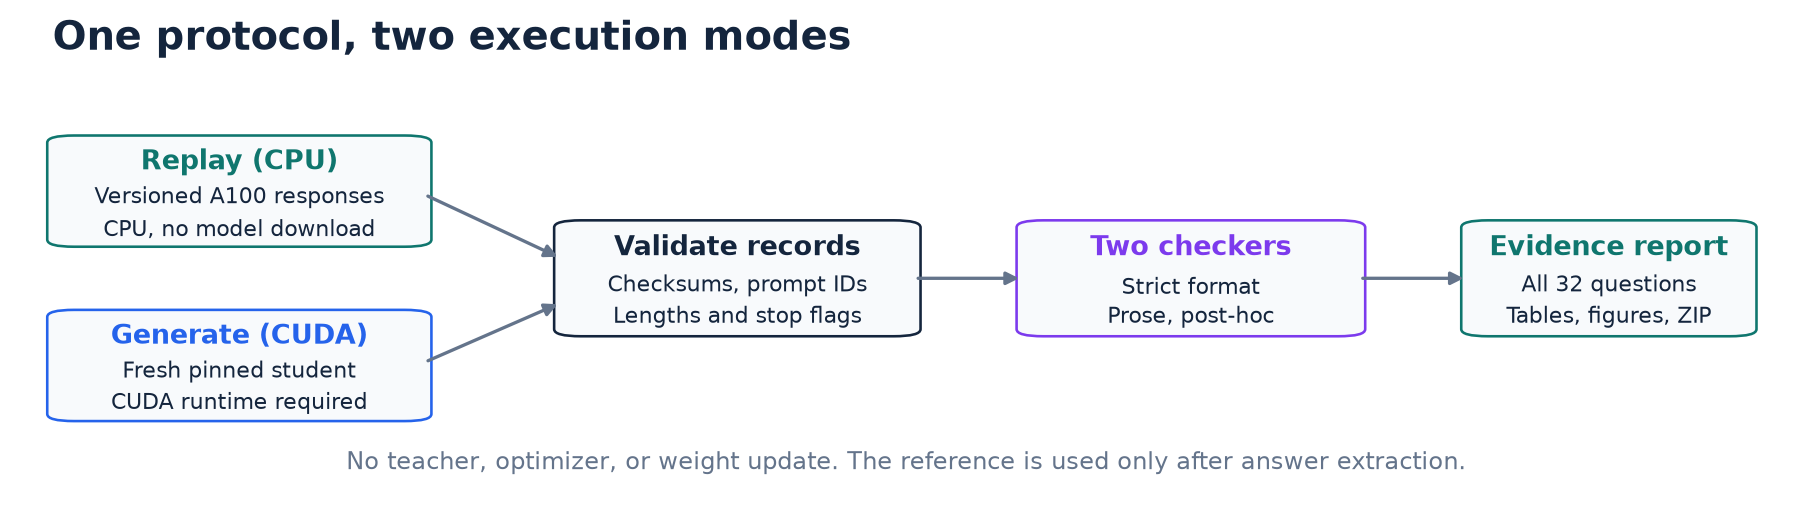

In [6]:
# Both paths use the same fixed protocol and the same scoring functions.
workflow_figure = plot_evaluation_workflow(FIGURES)
display(Image(filename=str(workflow_figure)))


*Figure 2. Replay validates original evidence without a model download. Generate
loads a fresh pinned student on CUDA and writes a new run. Neither path updates weights.*
[PNG](assets/02_baseline_evaluation/figures/evaluation_workflow.png) ·
[SVG](assets/02_baseline_evaluation/figures/evaluation_workflow.svg)

### 4.1 Choose replay or fresh GPU inference

In `generate` mode, the helper loads only the original student in BF16 when
supported, otherwise FP16; sets `eval()`; and uses `torch.inference_mode()`.
It verifies the pinned questions against the saved protocol before generating.
For each input, `input_ids` is `[1, prompt_length]` and generation returns
`[1, prompt_length + response_length]`. The exact prompt prefix must be preserved;
only the new response IDs are decoded and scored.

The explicit greedy `GenerationConfig` uses the recorded end tokens and budget.
It preserves the kernel's working PyTorch/CUDA installation. A seed does not
guarantee identical floating-point results across platforms or library versions;
the [PyTorch reproducibility guide](https://docs.pytorch.org/docs/stable/notes/randomness.html)
explains that limitation. Fresh inference must be verified on an actual CUDA runtime.

### Read the tensor shapes with a small example

If a question uses 8 prompt tokens and the student writes 5 response tokens:

```text
input_ids:     [1, 8]   = one example, eight prompt tokens
response_ids:  [1, 5]   = one example, five new tokens
complete_ids:  [1, 13]  = the original eight followed by the new five
```

The leading `1` is the **batch size**, not the number of words. Tokens can be word
pieces or punctuation, so token count is not word count. We score only the five
new tokens as the answer; decoding all thirteen would incorrectly include the
question in the answer text.

**Inference is not training.** `eval()` switches off training-specific model
behavior. `torch.inference_mode()` avoids recording gradients, which are needed
for weight updates but waste memory during evaluation. BF16 and FP16 store
floating-point model values compactly; token IDs remain integers.

A 512-token budget is a maximum, not a required answer length. Generation can
stop earlier on an end token. The helper processes the questions in turn, so
this cell can take time even when no progress text appears.


In [7]:
# Replay reuses saved evidence without importing CUDA or model libraries.
# Generate loads only the original pretrained student; the teacher is not used.
if MODE == "replay":
    active_run = recorded_run
else:
    # The setup cell installs Colab dependencies before any model imports.
    # Local CUDA users install requirements-generation.txt before starting Jupyter.
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    fresh_directory = PROJECT_ROOT / "results" / ("fresh_baseline_" + stamp)
    generate_fresh_baseline(protocol, fresh_directory)
    active_run = verify_recorded_run(fresh_directory)

response_rows = active_run["rows"]
scored_rows = active_run["annotations"]
scores = active_run["scores"]
print(f"Mode: {MODE} | New model inference: {MODE == 'generate'} | Questions: {len(response_rows)}")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Mode: generate | New model inference: True | Questions: 32


In [8]:
# These shapes are reconstructed from validated saved integer lists in replay mode.
# They verify stored dimensions, not a new forward pass or the teacher's logits.
shape_rows = [{
    "example_id": row["example_id"],
    "input_ids [batch, prompt]": f"[1, {row['prompt_length']}]",
    "response_ids [batch, response]": f"[1, {row['response_length']}]",
    "complete length": row["prompt_length"] + row["response_length"],
    "token-limit stop": row["hit_token_limit"],
} for row in response_rows]
display(pd.DataFrame(shape_rows).set_index("example_id").head(5))
assert all(row["response_length"] == len(row["response_token_ids"]) for row in response_rows)


,"input_ids [batch, prompt]","response_ids [batch, response]",complete length,token-limit stop
example_id,,,,
gsm8k/test/13,"[1, 86]","[1, 512]",598,True
gsm8k/test/51,"[1, 78]","[1, 357]",435,False
gsm8k/test/54,"[1, 111]","[1, 257]",368,False
gsm8k/test/61,"[1, 90]","[1, 145]",235,False
gsm8k/test/65,"[1, 76]","[1, 131]",207,False


---

<a id="results"></a>

## 5. Results and failure analysis

### 5.1 Original format score versus exploratory prose score

These scores use the **same responses from the same model**. Their difference is
a change in measurement, not a training gain. `None` means a checker could not
extract a final answer, not that the model returned an empty response.

**How to interpret our scores:** 0 strict matches means none of the responses
met the requested final-answer format. It does not prove every calculation was
wrong. The 17 prose matches mean the broader checker found 17 matching numbers.
The student did not learn between these two measurements: we changed how we
read the same answers, not the model's weights.

**Results checkpoint:** compare models using the same questions, prompts,
decoding settings, and checker. Changing several of these together makes it
hard to tell what caused a score difference.

### Why the strict checker returns zero on the recorded run

We checked all 32 original prompts and responses. Every prompt requests
`#### <number>`, but **none of the 32 responses contains `####` anywhere**.
Thirty responses end naturally; only two hit the token limit. Missing formatting,
rather than truncation or a broken parser, explains why nothing is extracted.

For example, `gsm8k/test/61` ends with `7. The final answer is $1430.`. The
strict checker rejects it, but accepts `#### 1430`. The prose checker extracts
1430 from the original sentence without rewriting the response.

The student is a pretrained base model, rather than a model trained specifically
to follow instructions, as its [model card](https://huggingface.co/Qwen/Qwen3-0.6B-Base#model-overview)
notes. That makes limited format compliance a plausible explanation, not a cause
we have isolated experimentally. Preserve the strict score. In a later supervised
stage, teach the requested format using separate training examples, then report
format compliance and numeric accuracy separately.


In [9]:
# Correct + parsed mismatch + unparsed must partition all N examples for each policy.
metrics = metric_rows(scored_rows, scores)
table = pd.DataFrame(metrics).set_index("checker")
display(table.assign(
    accuracy=table["accuracy"].map(lambda value: f"{value:.2%}"),
    parse_rate=table["parse_rate"].map(lambda value: f"{value:.2%}"),
))
if MODE == "replay":
    # Regression expectations for this immutable, versioned source run only.
    assert scores["strict"]["number_correct"] == 0
    assert scores["prose"]["number_correct"] == 17
    assert scores["prose"]["number_parsed"] == 28


,questions,correct,parsed_wrong,unparsed,accuracy,parse_rate
checker,,,,,,
Strict format (original),32,0,0,32,0.00%,0.00%
Prose (exploratory),32,17,11,4,53.12%,87.50%


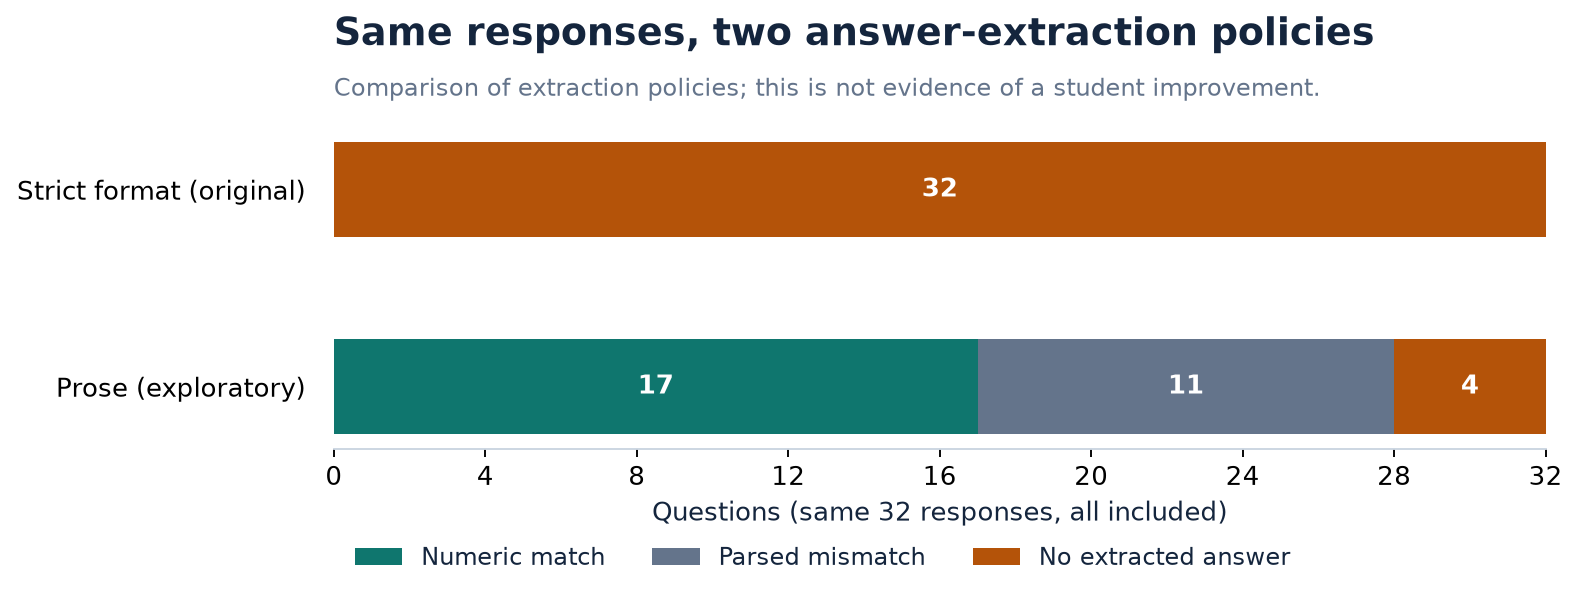

In [10]:
# Plot counts, not just percentages, so missing answers remain visible.
comparison_figure = plot_metric_comparison(metrics, FIGURES)
display(Image(filename=str(comparison_figure)))


*Figure 3. The original rule extracts no answers. The exploratory rule finds
numeric matches but still abstains on some responses. All questions remain in
each denominator. This is a parser-policy comparison, not a before/after model comparison.*
[PNG](assets/02_baseline_evaluation/figures/metric_comparison.png) ·
[SVG](assets/02_baseline_evaluation/figures/metric_comparison.svg)

### 5.2 Response length and stopping behavior

An end token means generation stopped naturally under its configured policy;
it does not guarantee a complete or correct solution. A token-limit stop can cut
off reasoning or repetition. We report these diagnostics without using them to
drop difficult examples from the score.

For example, an answer can reach 512 tokens because it repeats itself, not
because the problem required a long solution. Conversely, a short answer can be
wrong. The length plot helps diagnose stopping behavior; it is not a quality score.
Our conservative prose checker abstains on token-limit stops because the final
conclusion may be unfinished, even if a matching number appeared earlier.


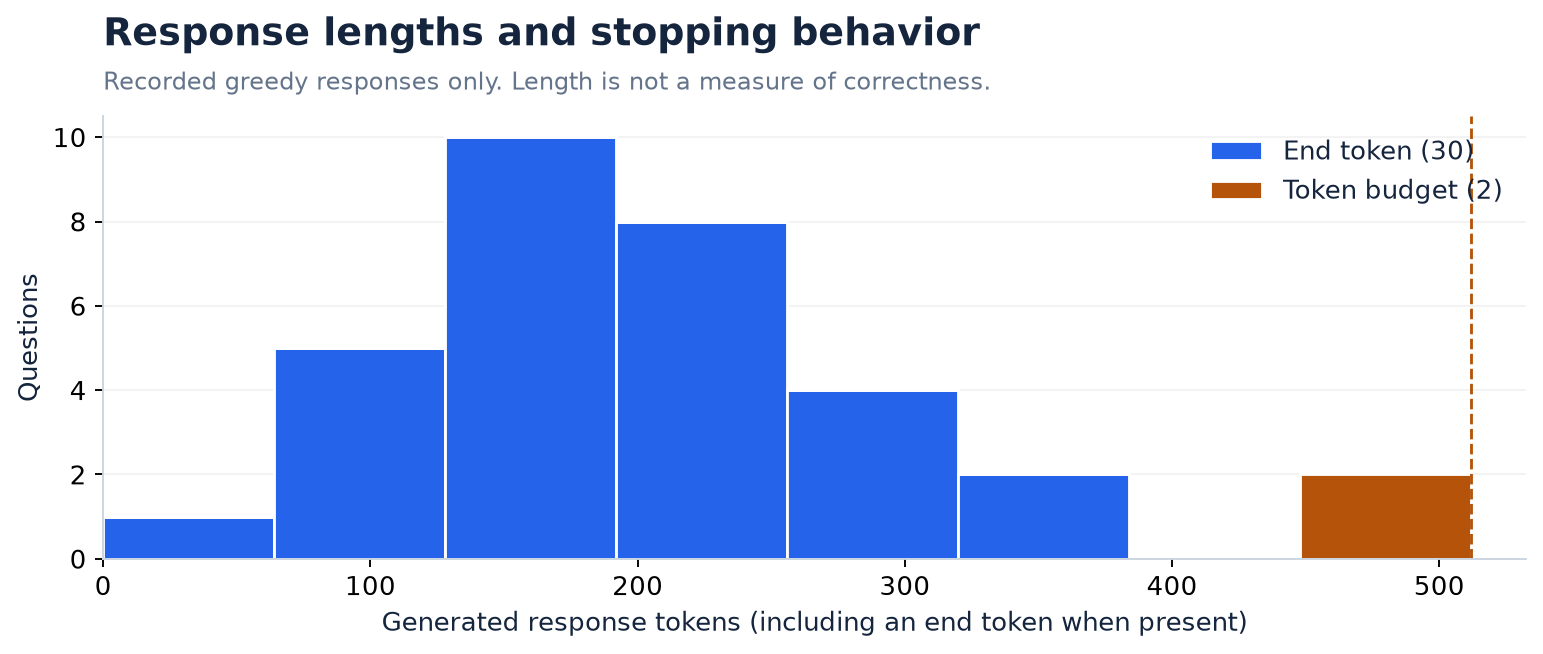

Token-limit stops: 2/32
Mean response length: 214.25 tokens


In [11]:
# Length includes an end token when present, matching the original stored IDs.
budget = active_run["manifest"]["protocol"]["generation_config"]["max_new_tokens"]
length_figure = plot_response_lengths(response_rows, budget, FIGURES)
display(Image(filename=str(length_figure)))
print(f"Token-limit stops: {sum(row['hit_token_limit'] for row in response_rows)}/{len(response_rows)}")
print(f"Mean response length: {sum(row['response_length'] for row in response_rows) / len(response_rows):.2f} tokens")


*Figure 4. Token counts from the recorded response IDs, including both budget
stops. This is a generation diagnostic, not a training curve or a latency benchmark.*
[PNG](assets/02_baseline_evaluation/figures/response_lengths.png) ·
[SVG](assets/02_baseline_evaluation/figures/response_lengths.svg)

### 5.3 Audit the decisions, including abstentions

The table below exposes the chosen number and exact concluding text. A parser
failure is different from a parsed numeric mismatch. The prose checker cannot
resolve every sentence containing several numbers; those cases remain reviewable
in the original JSONL rather than being guessed from the reference.

**Three outcomes to keep separate:**

1. **Numeric match:** the checker extracted a number equal to the reference.
2. **Parsed mismatch:** it extracted a clear answer, but the number differs.
3. **Abstention:** it could not safely select a final number.

For example, a sentence containing a price, a quantity, and a total may be hard
for a rule-based extractor to interpret. Abstaining keeps that uncertainty
visible. A blank, `None`, or `NaN` in the extracted-answer column can represent
this missing value; it does not mean the student wrote no text.


In [12]:
# Audit all decisions in the exported CSV; display a compact selection here.
audit_table = pd.DataFrame(scored_rows).set_index("example_id")
display(audit_table[["expected_answer", "prose_answer", "extraction_method", "extraction_evidence"]]
        .head(5).rename(columns={"expected_answer": "Reference", "prose_answer": "Extracted",
                               "extraction_method": "Method", "extraction_evidence": "Evidence"}))
display(audit_table[audit_table["prose_answer"].isna()]
        [["expected_answer", "extraction_reason", "extraction_evidence"]]
        .rename(columns={"expected_answer": "Reference", "extraction_reason": "Reason",
                         "extraction_evidence": "Evidence"}))


,Reference,Extracted,Method,Evidence
example_id,,,,
gsm8k/test/13,18,NaN,unparsed,
gsm8k/test/51,5,54,concluding_sentence,"So, it takes Tom 54 minutes to get back."
gsm8k/test/54,40,55,concluding_sentence,"So, the Doubtfire family now has 55 kittens."
gsm8k/test/61,1430,1430,explicit_answer,The final answer is $1430.
gsm8k/test/65,36,NaN,unparsed,"So, Jim spends 12 hours on TV and reading in 4 weeks."


,Reference,Reason,Evidence
example_id,,,
gsm8k/test/13,18,token_limit_stop,
gsm8k/test/65,36,no_clear_final_answer,"So, Jim spends 12 hours on TV and reading in 4 weeks."
gsm8k/test/451,11050,no_clear_final_answer,"Therefore, Bentley paid $11050 to fill 170 balloons after the price ..."
gsm8k/test/1034,66,token_limit_stop,


### 5.4 A correct number is not a verified explanation

One recorded response computes `35 / 7 = 5`, the correct numeric answer for the
whole flock's daily insect requirement, but concludes that **each duck** needs
that amount. Both the unit scope and the reasoning claim matter; a numeric-only
metric does not catch that distinction. This is why we report *numeric agreement*,
not verified reasoning accuracy.

The next display preserves that response verbatim from the recorded run. It is an
audit example, not an additional metric or a correction to the reference labels.

**A concrete unit check:** ten ducks need `10 * 3.5 = 35` pounds per week.
The whole flock therefore needs `35 / 7 = 5` pounds per day, while one duck needs
`3.5 / 7 = 0.5` pounds per day. Saying “each duck needs 5” includes the expected
number but answers a different question. A numeric match is useful evidence,
but human inspection is still needed to spot this kind of mistake.


In [13]:
# This case illustrates a known metric limitation, not a rule tuned to award credit.
semantic_case = next(row for row in recorded_run["rows"] if row["example_id"] == "gsm8k/test/191")
print("Recorded question:", semantic_case["question"])
print("\nRecorded conclusion:", semantic_case["response_text"].strip().splitlines()[-1])
print("Reference number:", semantic_case["expected_answer"])


Recorded question: Ducks need to eat 3.5 pounds of insects each week to survive. If there is a flock of ten ducks, how many pounds of insects do they need per day?

Recorded conclusion: So, each duck in the flock needs 5 pounds of insects per day to survive.
Reference number: 5


---

<a id="reproducibility"></a>

## 6. Reproducibility, export, and validation boundaries

| What is checked here | What that establishes |
| :--- | :--- |
| Four source-file hashes and protocol hash | The recorded input evidence has not changed |
| Question IDs, prompts, reference numbers | Both scoring policies use the same selected examples |
| Token-list lengths and EOS/budget flags | Stored shapes and stopping metadata are internally consistent |
| Independent strict-score recomputation | The original 0/32 result has not been silently replaced |
| Prose evidence and versioned rules | Extracted values can be audited without a model judge |
| Tests and clean-kernel replay | Analysis code runs sequentially from empty notebook state |

An [independent pinned-source check](assets/02_baseline_evaluation/source_verification.json)
also reproduced all 32 prompt tokenizations, response-ID decodes, and reference
answers directly from the recorded tokenizer and dataset revisions, without
loading model weights. This check is separate from the offline replay so that
the default notebook does not require network access.

Replay cannot rerun the historical GPU computation, recover teacher logits that
were never saved here, or prove improved performance after training. The fresh
generation branch requires a working Colab GPU and matching dependencies. Source
code checks are not a substitute for that inference run.

The export stores both scores, source fingerprints, the exact checker source,
analysis-library versions, code hashes, and the recorded GPU environment **separately**.
New exports also include `raw_run/`: the original manifest, responses and token IDs,
results, summary, and checksums. This makes the download self-contained.
A new folder is created for each report; it never overwrites the original run.

### What the exported files let someone else do

A **manifest** is the experiment's packing list: model, data, settings, and
runtime details. **JSONL** stores one full response record per line, including
token IDs. **CSV** makes per-question scores easy to inspect in a table, and a
**summary** collects the aggregate counts. The analysis export also preserves
the checker code, so a future reader can see precisely which rule produced a score.

There are two separate claims to verify: “these are the same stored answers”
and “this code can generate new answers.” File checks and replay support the
first; an actual completed CUDA generation run supports the second. Neither
alone proves training improved the student.


In [14]:
# Export a new analysis bundle. Results are ignored by Git; the immutable source
# snapshot and the notebook's verified figures are versioned separately.
# New bundles include raw_run/ with original responses, token IDs, and checksums.
analysis_archive = export_analysis(PROJECT_ROOT, active_run, execution_mode=MODE)
print("Analysis archive:", analysis_archive.relative_to(PROJECT_ROOT))
print("Recorded inference environment:", active_run["manifest"]["environment"]["gpu"])
print("Current analysis environment:", analysis_environment()["platform"], "Python", analysis_environment()["python"])
print("Fresh inference in this execution:", MODE == "generate")


Analysis archive: results/baseline_analysis_20261027T220031049647Z.zip
Recorded inference environment: NVIDIA A100-SXM4-80GB
Current analysis environment: Linux Python 3.13.16
Fresh inference in this execution: True


### Save before leaving Colab

`DOWNLOAD_REPORT = True` below requests a ZIP download from Colab. Set it to
`False` to skip automatic downloads, or use Colab's Files panel. Also save the executed notebook. Colab storage is temporary; no Google
Drive is used. In local Jupyter, the ZIP is under the project's `results/` folder.

**Server storage versus your computer:** a path beginning with `/content/`
is on Colab's temporary server. Creating a ZIP there does not automatically put
it in your Downloads folder. The download cell requests that transfer; if your
VS Code connection cannot open it, use Colab's browser Files panel. Keep the ZIP
and executed notebook before the runtime disconnects.

The saved output below records an earlier successful export. Exports created
with the finalized helper also include `raw_run/`. To re-export an existing run,
first update the runtime's project checkout and load the new helper, then export
that saved run. Editing the local notebook does not update an existing remote
`/content/` checkout automatically. The earlier ZIP is not retroactively updated.


In [16]:
# Download the bundle in Colab; switch this flag off to avoid repeated downloads.
# Local replay only prints the path and does not open a browser.
DOWNLOAD_REPORT = True
if DOWNLOAD_REPORT and IN_COLAB:
    from google.colab import files
    files.download(str(analysis_archive))
elif DOWNLOAD_REPORT:
    print("Open the ZIP in the project's results/ folder.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

<a id="conclusions"></a>

## 7. Conclusions and next experiment

The recorded run has **0/32 strict-format matches** and **17/32 exploratory
prose-extracted numeric matches (53.125%)**. The second checker reads 28 responses;
11 of those have a different number from the reference, and 4 responses remain
unparsed. Two responses reached the token budget. These are computations over
the same saved outputs, not evidence that the model improved.

The important engineering result is a baseline we can inspect and replay: exact
source revisions, preserved token IDs, explicit scoring contracts, evidence for
each extraction, and no hidden change to the original score.

### Limits that matter for interpretation

- **Small sample:** 32 questions cannot establish broad reasoning ability.
- **Post-hoc metric:** prose rules were informed by this run; freeze them and use
  untouched examples for a stronger future comparison.
- **Heuristic extraction:** clear answers outside the recognized styles can be
  missed. Numeric matches do not validate reasoning or units.
- **One decoding policy:** greedy performance does not describe sampled behavior.
- **No training evidence here:** there is no teacher evaluation, learning curve,
  or independently measured post-distillation improvement in these artifacts.

Next, use separate training data in [`03_sft_cold_start.ipynb`](03_sft_cold_start.ipynb).
Keep this baseline intact. Later distillation should generate fresh student
trajectories and use the same evaluation definitions on reserved examples.

**In simple terms:** we gave the original student a small test, kept exactly what
it wrote, and checked both whether it followed the answer format and whether we
could read a matching final number. We now have a clearer starting point for later
training, with the limits of that measurement visible.

### What we achieved, in the simplest terms

We gave the original student 32 math questions and kept what it actually wrote.
We checked its answer format, tried a separate rule for reading prose answers,
and made the successes, mistakes, and unreadable conclusions visible. We also
saved enough information for someone else to inspect how the scores were made.
**We tested the student; we did not teach it anything in this notebook.**

Notebook 03 will prepare the supervised cold start using separate training data.
Later, distillation can ask the frozen teacher for feedback on new student-written
responses. To judge whether either stage helped, we will need a fair comparison
under a fixed evaluation protocol, not just a lower training loss.

### References

- [Generalized Knowledge Distillation, Sections 3–3.1](https://arxiv.org/html/2306.13649v3#S3): student-generated prefixes and divergence objectives.
- [GSM8K dataset](https://huggingface.co/datasets/openai/gsm8k) and [original repository](https://github.com/openai/grade-school-math): questions, reference-answer format, and MIT license.
- [Transformers generation configuration](https://huggingface.co/docs/transformers/main_classes/text_generation): greedy decoding and response-token budgets.
- [PyTorch KL conventions](https://docs.pytorch.org/docs/stable/generated/torch.nn.KLDivLoss.html) and [reproducibility notes](https://docs.pytorch.org/docs/stable/notes/randomness.html).
- [Reusable evaluation code](../src/evaluation.py), [inference and record validation](../src/baseline.py), and [tests](../tests/).
